<a href="https://colab.research.google.com/github/JackMeck/MMA3001-Project-Smart-Infrastructure/blob/main/Final_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MMA3001 project (simplified): room occupancy from environmental sensors
One sensor, one room. Sensor readings -> predicted headcount. Two models (Ridge, SVR) are compared against a simple time-of-week baseline using time-ordered cross-validation and one final hold-out test.

## 1. Data import and preparation

In [1]:
# ===== 1. SETTINGS + DATA FILES =====
import os, glob, zipfile, json
import numpy as np, pandas as pd

DRIVE_DIR = '/content/drive/MyDrive/ENG3001'
DATA_DIR = '/content/unzipped_data'
ENV_SENSOR_ID = '6012002000869'
FLOORSPACE = '941f0352-bb69-47d0-a9c5-ac29eb4f7319'     # the one room we predict
WINDOW_START, WINDOW_END = '2024-02-29', '2024-06-14'   # period with real sensor data
TZ = 'Australia/Melbourne'

try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass

os.makedirs(DATA_DIR, exist_ok=True)
ENV_CSV = f'{DATA_DIR}/5EnvSensor_MayToDec2024_180kRows.csv'
OCC_CSV = f'{DATA_DIR}/5occupancySensor_MayToDec2024_9MRows.csv'
for z in glob.glob(f'{DRIVE_DIR}/*Sensor*.zip'):
    with zipfile.ZipFile(z) as f:
        for name in f.namelist():
            if not os.path.exists(os.path.join(DATA_DIR, name)):
                f.extract(name, DATA_DIR)
print(os.listdir(DATA_DIR))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['5EnvSensor_MayToDec2024_180kRows.csv', '5occupancySensor_MayToDec2024_9MRows.csv']


In [2]:
# ===== 2. Loading Environmental Data =====
VARS = {'Carbon dioxide': 'co2', 'Temperature': 'temperature', 'Humidity': 'humidity',
        'Light Volatile Organic Compounds': 'voc', 'Particulate matter 2.5': 'pm2_5'}

raw = pd.read_csv(ENV_CSV, usecols=['sensorid', 'jsondata'])
raw = raw[raw['sensorid'].astype(str) == ENV_SENSOR_ID]

# each row holds a list of variables, each with (time, value) pairs; skip entries with an errorCode
rows = {}
for js in raw['jsondata']:
    for rec in json.loads(js):
        name = VARS.get(rec.get('variable', {}).get('name'))
        if name is None:
            continue
        for v in rec.get('values', []):
            if 'value' in v and 'errorCode' not in v:
                rows.setdefault(v['time'], {})[name] = v['value']

env = pd.DataFrame.from_dict(rows, orient='index').apply(pd.to_numeric, errors='coerce').sort_index()
env.index = pd.to_datetime(pd.to_numeric(env.index), unit='s', utc=True).tz_convert(TZ).tz_localize(None)
env = env.dropna(subset=['co2'])

# the sensor repeats one fixed reading (a placeholder, not a measurement) - drop any CO2/temp/humidity
# combination that makes up 5% or more of the records
key = ['co2', 'temperature', 'humidity']
counts = env[key].value_counts()
print(len(raw), 'raw rows |', len(env), 'rows after error-code filter')
print(env[['co2', 'temperature', 'humidity']].value_counts().head(3))
placeholder = counts[counts / len(env) >= 0.05].index
print('placeholder readings dropped:', list(placeholder))
env = env[~env.set_index(key).index.isin(placeholder)]
env = env[~env.index.duplicated(keep='last')].sort_index()

# regular 15-minute grid (each reading goes to the NEXT grid point, so no future information), short gaps filled
env = env.loc[WINDOW_START:WINDOW_END]
env.index = env.index.ceil('15min')
env = env.groupby(level=0).mean()
env = env.reindex(pd.date_range(env.index.min(), env.index.max(), freq='15min')).ffill(limit=3)
print(env.shape, '| first', env.index.min(), '| last', env.index.max())

29341 raw rows | 13800 rows after error-code filter
co2  temperature  humidity
546  23.5         40          7
487  23.3         46          6
448  23.3         42          6
Name: count, dtype: int64
placeholder readings dropped: []
(10124, 5) | first 2024-02-29 17:15:00 | last 2024-06-14 04:00:00


In [3]:
# ===== 3. Loads Occupancy Data =====
# the file is ~9M rows, so read it in chunks and keep only our room
parts = [c[c['floorspaceid'] == FLOORSPACE]
         for c in pd.read_csv(OCC_CSV, usecols=['floorspaceid', 'headcount', 'collecteddate'], chunksize=1_000_000)]
ev = pd.concat(parts)
t = pd.to_datetime(ev['collecteddate'], format='ISO8601', utc=True).dt.tz_convert(TZ).dt.tz_localize(None)
occ = pd.Series(pd.to_numeric(ev['headcount'], errors='coerce').to_numpy(), index=t).dropna().sort_index()
occ = occ[~occ.index.duplicated(keep='last')]

# headcount is a held state: carry the last value forward (max 3 days), then average over each 15-min interval
occ = occ.resample('1min').last().ffill(limit=4320)
occ = occ.resample('15min', closed='right', label='right').mean().rename('occupancy')
print(len(ev), 'events ->', occ.notna().sum(), '15-min rows')

1975423 events -> 83360 15-min rows


In [4]:
# ===== 4. Builds Modelling Table =====
env['co2_chg1h'] = env['co2'].diff(4)          # 4 x 15 min = 1 hour; uses past readings only
SENSOR_COLS = list(env.columns)

df = env.join(occ, how='inner').dropna(subset=['occupancy', 'co2'])
df['hour'] = df.index.hour + df.index.minute / 60
df['weekend'] = (df.index.dayofweek >= 5).astype(int)
print(df.shape)
print(df.describe().round(2).to_string())

(10124, 9)
            co2  humidity  temperature       voc     pm2_5  co2_chg1h  occupancy      hour   weekend
count  10124.00  10124.00     10124.00  10124.00  10124.00   10120.00   10124.00  10124.00  10124.00
mean     473.92     45.13        23.11     10.36      4.73       0.02       0.65     11.88      0.28
std       39.14      7.46         1.18     35.23      7.60      18.71       0.94      6.94      0.45
min      403.00     26.00        19.00      0.00      0.00    -118.50       0.00      0.00      0.00
25%      445.00     40.00        22.50      0.00      1.50     -10.00       0.00      5.75      0.00
50%      462.50     45.00        23.30      0.00      2.50       0.00       0.13     12.00      0.00
75%      494.00     49.50        23.80      1.50      4.00      10.00       1.07     18.00      1.00
max      646.00     75.00        28.50    729.00     79.00     116.00       6.93     23.75      1.00


## 2. Candidate models and validation setup
Defines the schedule baseline, linear regression and SVR, the chronological train/test split, and the first cross-validation comparison.

In [5]:
# ===== 5. Candidate models, training/testing split, cross validation  =====
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR

class ScheduleBaseline(BaseEstimator, RegressorMixin):
    # predicts the training mean for the same (weekend, hour) slot, ignoring all sensors
    def _key(self, X):
        return np.array([f"{int(w)}_{int(round(h))}" for w, h in zip(X['weekend'], X['hour'])])
    def fit(self, X, y):
        self.table_ = pd.Series(np.asarray(y)).groupby(self._key(X)).mean().to_dict()
        self.mean_ = float(np.mean(y))
        return self
    def predict(self, X):
        return np.array([self.table_.get(k, self.mean_) for k in self._key(X)])

def sensors():
    return ColumnTransformer([('s', 'passthrough', SENSOR_COLS)])

MODELS = {
    'Baseline (schedule)': lambda: ScheduleBaseline(),
    'Linear Regression':               lambda: make_pipeline(sensors(), SimpleImputer(strategy='median'), StandardScaler(), LinearRegression()),
    'SVR':                 lambda: make_pipeline(sensors(), SimpleImputer(strategy='median'), StandardScaler(), SVR(C=10, epsilon=0.5)),
}

def metrics(y, p):
    p = np.clip(p, 0, None)
    return {'MAE': mean_absolute_error(y, p), 'RMSE': mean_squared_error(y, p) ** 0.5,
            'R2': r2_score(y, p), 'bias': float(np.mean(p - y))}

# chronological split with a 2-hour (8 step) gap
FEATURES = SENSOR_COLS + ['hour', 'weekend']
X, y = df[FEATURES], df['occupancy']
cut = int(0.8 * len(df))
X_tr, y_tr = X.iloc[:cut - 8], y.iloc[:cut - 8]
X_te, y_te = X.iloc[cut:], y.iloc[cut:]
print('train', X_tr.index.min(), '->', X_tr.index.max(), '| test', X_te.index.min(), '->', X_te.index.max())

# time-series cross-validation on the training period
cv_rows = []
for name, make in MODELS.items():
    for tr, va in TimeSeriesSplit(n_splits=5, gap=8).split(X_tr):
        m = make().fit(X_tr.iloc[tr], y_tr.iloc[tr])
        cv_rows.append({'model': name, **metrics(y_tr.iloc[va], m.predict(X_tr.iloc[va]))})
cv = pd.DataFrame(cv_rows).groupby('model').mean().loc[list(MODELS)]
print('CROSS-VALIDATION (training period, mean of 5 folds)')
print(cv.round(3).to_string())

train 2024-02-29 17:15:00 -> 2024-05-23 23:45:00 | test 2024-05-24 02:00:00 -> 2024-06-14 04:00:00
CROSS-VALIDATION (training period, mean of 5 folds)
                       MAE   RMSE     R2   bias
model                                          
Baseline (schedule)  0.476  0.724  0.428 -0.084
Linear Regression    0.524  0.720  0.441  0.071
SVR                  0.587  0.767  0.355  0.128


## 3. Sensitivity analysis and optimisation
### 3a. Feature ablation: which inputs matter?

In [6]:
# ===== 6. Defines features =====
from sklearn.linear_model import LinearRegression

def linear_on(cols):
    # linear model that only sees the listed columns
    return lambda: make_pipeline(ColumnTransformer([('c', 'passthrough', cols)]),
                                 SimpleImputer(strategy='median'), StandardScaler(), LinearRegression())

VARIANTS = {
    'Full (all sensors + time)': linear_on(FEATURES),
    'Lean (CO2 + temp + time)':  linear_on(['co2', 'temperature', 'hour', 'weekend']),
    'CO2 + time':                linear_on(['co2', 'hour', 'weekend']),
    'Time only (no sensors)':    linear_on(['hour', 'weekend']),
    'Sensors only (no time)':    linear_on(SENSOR_COLS),
}

rows = []
for name, make in VARIANTS.items():
    cv = [metrics(y_tr.iloc[va], make().fit(X_tr.iloc[tr], y_tr.iloc[tr]).predict(X_tr.iloc[va]))
          for tr, va in TimeSeriesSplit(n_splits=5, gap=8).split(X_tr)]
    cv = pd.DataFrame(cv).mean()
    te = metrics(y_te, make().fit(X_tr, y_tr).predict(X_te))
    rows.append({'variant': name, 'CV MAE': cv['MAE'], 'CV RMSE': cv['RMSE'],
                 'Test MAE': te['MAE'], 'Test RMSE': te['RMSE'], 'Test R2': te['R2']})
ablation = pd.DataFrame(rows).set_index('variant')
print('FEATURE ABLATION (linear model)')
print(ablation.round(3).to_string())

FEATURE ABLATION (linear model)
                           CV MAE  CV RMSE  Test MAE  Test RMSE  Test R2
variant                                                                 
Full (all sensors + time)   0.513    0.721     0.415      0.556   -0.096
Lean (CO2 + temp + time)    0.502    0.720     0.376      0.530    0.004
CO2 + time                  0.562    0.754     0.395      0.546   -0.060
Time only (no sensors)      0.670    0.919     0.633      0.758   -1.043
Sensors only (no time)      0.524    0.720     0.403      0.546   -0.060


In [7]:
# one-at-a-time removal from the full linear model (CV only)
def cv_scores(make):
    f = [metrics(y_tr.iloc[va], make().fit(X_tr.iloc[tr], y_tr.iloc[tr]).predict(X_tr.iloc[va]))
         for tr, va in TimeSeriesSplit(n_splits=5, gap=8).split(X_tr)]
    return pd.DataFrame(f).mean()

base = cv_scores(linear_on(FEATURES))
rows = [{'dropped input': '(none, full model)', 'CV MAE': base['MAE'], 'CV RMSE': base['RMSE'], 'change in RMSE': 0.0}]
for col in FEATURES:
    s = cv_scores(linear_on([c for c in FEATURES if c != col]))
    rows.append({'dropped input': col, 'CV MAE': s['MAE'], 'CV RMSE': s['RMSE'], 'change in RMSE': s['RMSE'] - base['RMSE']})
loo = pd.DataFrame(rows).set_index('dropped input')
print('LEAVE-ONE-OUT (full linear model, cross-validation)')
print(loo.round(3).to_string())

LEAVE-ONE-OUT (full linear model, cross-validation)
                    CV MAE  CV RMSE  change in RMSE
dropped input                                      
(none, full model)   0.513    0.721           0.000
co2                  0.592    0.854           0.134
humidity             0.508    0.721          -0.000
temperature          0.572    0.753           0.033
voc                  0.513    0.720          -0.000
pm2_5                0.509    0.723           0.002
co2_chg1h            0.511    0.717          -0.003
hour                 0.524    0.723           0.002
weekend              0.516    0.720          -0.001


### 3b. SVR settings and training-data requirement
Settings are judged on cross-validation only, never on the test set.

In [8]:
# ===== 7. SVR settings, defines Lean and SVR_on =====
def cv_mae(make):
    return np.mean([metrics(y_tr.iloc[va], make().fit(X_tr.iloc[tr], y_tr.iloc[tr]).predict(X_tr.iloc[va]))['MAE']
                    for tr, va in TimeSeriesSplit(n_splits=5, gap=8).split(X_tr)])

def pipe(model):
    return lambda: make_pipeline(sensors(), SimpleImputer(strategy='median'), StandardScaler(), model)

# --- (a) SVR settings on the lean inputs, judged on cross-validation only ---
LEAN = ['co2', 'temperature', 'hour', 'weekend']

def svr_on(cols, C, epsilon):
    return lambda: make_pipeline(ColumnTransformer([('c', 'passthrough', cols)]),
                                 SimpleImputer(strategy='median'), StandardScaler(),
                                 SVR(C=C, epsilon=epsilon))

svr_C = [0.01, 0.03, 0.1, 0.3, 1]
svr_eps = [0,0.001,0.01, 0.05, 0.1, 0.2]
svr_cv = pd.DataFrame({e: {C: cv_mae(svr_on(LEAN, C, e)) for C in svr_C} for e in svr_eps})
svr_cv.index.name, svr_cv.columns.name = 'C', 'epsilon'
print('SVR (lean inputs): CV MAE vs C (rows) and epsilon (columns)'); print(svr_cv.round(3).to_string())
C_best, eps_best = svr_cv.stack().idxmin()
print(f'best SVR: C = {C_best}, epsilon = {eps_best}')

# --- (b) data requirement: how much training data does the linear model need? ---
# validate on the last 20% of the training period (after a gap), train on the earliest fractions of what is left
v0 = int(0.8 * len(X_tr))
X_val, y_val = X_tr.iloc[v0:], y_tr.iloc[v0:]
X_pool, y_pool = X_tr.iloc[:v0 - 8], y_tr.iloc[:v0 - 8]
lin = MODELS[[k for k in MODELS if 'inear' in k][0]]
curve = {}
for frac in [0.1, 0.25, 0.5, 0.75, 1.0]:
    n = int(frac * len(X_pool))
    curve[f'{frac:.0%} ({n} rows)'] = metrics(y_val, lin().fit(X_pool.iloc[:n], y_pool.iloc[:n]).predict(X_val))
print('\nLINEAR MODEL: validation error vs amount of training data')
print(pd.DataFrame(curve).T[['MAE', 'RMSE', 'R2']].round(3).to_string())

SVR (lean inputs): CV MAE vs C (rows) and epsilon (columns)
epsilon  0.000  0.001  0.010  0.050  0.100  0.200
C                                                
0.01     0.454  0.454  0.453  0.456  0.463  0.487
0.03     0.434  0.434  0.434  0.437  0.443  0.463
0.10     0.425  0.425  0.426  0.429  0.435  0.452
0.30     0.425  0.425  0.425  0.430  0.435  0.449
1.00     0.427  0.427  0.427  0.431  0.436  0.450
best SVR: C = 0.3, epsilon = 0.0

LINEAR MODEL: validation error vs amount of training data
                    MAE   RMSE     R2
10% (646 rows)    0.597  0.776  0.403
25% (1616 rows)   0.620  0.784  0.390
50% (3232 rows)   0.605  0.780  0.398
75% (4848 rows)   0.603  0.781  0.395
100% (6464 rows)  0.626  0.801  0.364


## 4. Final model selection
Final models chosen from the cross-validation evidence in section 3.

In [9]:
# ===== 8. Final Model Selection =====
# FINAL MODEL SELECTION
# chosen using cross-validation only (cells 5, 7 and 9); the test set has not been used to choose anything
FINAL_MODELS = {
    'Baseline (schedule)': MODELS['Baseline (schedule)'],
    'Linear Regression':   linear_on(LEAN),                          # lean model from cell 7
    'SVR':                 svr_on(LEAN, C=0.3, epsilon=0.01),        # replace with the best from cell 9
}
print('Final models:', list(FINAL_MODELS))

Final models: ['Baseline (schedule)', 'Linear Regression', 'SVR']


In [10]:
# data requirement for the final models (validation block = last 20% of the training period, after a gap)
v0 = int(0.8 * len(X_tr))
X_val, y_val = X_tr.iloc[v0:], y_tr.iloc[v0:]
X_pool, y_pool = X_tr.iloc[:v0 - 8], y_tr.iloc[:v0 - 8]

curve = {}
for frac in [0.1, 0.25, 0.5, 0.75, 1.0]:
    n = int(frac * len(X_pool))
    row = {}
    for name in ['Linear Regression', 'SVR']:
        m = FINAL_MODELS[name]().fit(X_pool.iloc[:n], y_pool.iloc[:n])
        row[f'{name} val MAE'] = metrics(y_val, m.predict(X_val))['MAE']
        row[f'{name} train MAE'] = metrics(y_pool.iloc[:n], m.predict(X_pool.iloc[:n]))['MAE']
    curve[f'{frac:.0%} ({n} rows)'] = row
print('DATA REQUIREMENT: FINAL MODELS')
print(pd.DataFrame(curve).T.round(3).to_string())

DATA REQUIREMENT: FINAL MODELS
                  Linear Regression val MAE  Linear Regression train MAE  SVR val MAE  SVR train MAE
10% (646 rows)                        0.570                        0.453        0.574          0.293
25% (1616 rows)                       0.565                        0.525        0.505          0.357
50% (3232 rows)                       0.556                        0.432        0.510          0.311
75% (4848 rows)                       0.570                        0.449        0.525          0.327
100% (6464 rows)                      0.600                        0.488        0.517          0.372


## 5. Final evaluation
### 5a. Cross-validation of the final models

In [11]:
# ===== 9. Cross Validation Table For Final Models =====
cv_final = []
for name, make in FINAL_MODELS.items():
    for tr, va in TimeSeriesSplit(n_splits=5, gap=8).split(X_tr):
        m = make().fit(X_tr.iloc[tr], y_tr.iloc[tr])
        cv_final.append({'model': name, **metrics(y_tr.iloc[va], m.predict(X_tr.iloc[va]))})
cv_final = pd.DataFrame(cv_final).groupby('model').mean().loc[list(FINAL_MODELS)]
print('CROSS-VALIDATION OF FINAL MODELS (training period, mean of 5 folds)')
print(cv_final.round(3).to_string())

CROSS-VALIDATION OF FINAL MODELS (training period, mean of 5 folds)
                       MAE   RMSE     R2   bias
model                                          
Baseline (schedule)  0.476  0.724  0.428 -0.084
Linear Regression    0.502  0.720  0.442  0.020
SVR                  0.425  0.686  0.498 -0.165


### 5b. Computational cost

In [12]:
# ===== 10. Timing Of Final Models =====
import time, tracemalloc

def time_it(fn, repeats=5):
    best = float('inf')
    for _ in range(repeats):
        t0 = time.perf_counter(); fn(); best = min(best, time.perf_counter() - t0)
    return best

perf = []
for name, make in FINAL_MODELS.items():
    fit_s = time_it(lambda: make().fit(X_tr, y_tr))
    m = make().fit(X_tr, y_tr)
    pred_s = time_it(lambda: m.predict(X_te))
    tracemalloc.start(); make().fit(X_tr, y_tr)
    peak_mb = tracemalloc.get_traced_memory()[1] / 1e6; tracemalloc.stop()
    perf.append({'model': name, 'fit (ms)': fit_s * 1e3, 'predict (ms)': pred_s * 1e3,
                 'predict per 1000 rows (ms)': pred_s * 1e3 / len(X_te) * 1000, 'peak fit memory (MB)': peak_mb})
perf = pd.DataFrame(perf).set_index('model')
print(f'COMPUTATIONAL COST (train rows = {len(X_tr)}, test rows = {len(X_te)}; best of 5)')
print(perf.round(3).to_string())

COMPUTATIONAL COST (train rows = 8091, test rows = 2025; best of 5)
                     fit (ms)  predict (ms)  predict per 1000 rows (ms)  peak fit memory (MB)
model                                                                                        
Baseline (schedule)     7.824         2.263                       1.117                 0.954
Linear Regression       8.309         2.141                       1.057                 1.483
SVR                  2395.153      1096.348                     541.406                 1.483


### 5c. Final test (held-out data, run once)

In [13]:
# ===== 11. Final Test =====
test_rows, preds = {}, {}
for name, make in FINAL_MODELS.items():
    m = make().fit(X_tr, y_tr)
    preds[name] = np.clip(m.predict(X_te), 0, None)
    test_rows[name] = metrics(y_te, preds[name])
test = pd.DataFrame(test_rows).T
print('FINAL TEST')
print(test.round(3).to_string())
print('\nMAE improvement over baseline:')
print((1 - test['MAE'] / test.loc['Baseline (schedule)', 'MAE']).round(3).to_string())

FINAL TEST
                       MAE   RMSE     R2   bias
Baseline (schedule)  0.557  0.779 -1.156  0.488
Linear Regression    0.376  0.530  0.004  0.176
SVR                  0.236  0.402  0.426  0.063

MAE improvement over baseline:
Baseline (schedule)    0.000
Linear Regression      0.325
SVR                    0.576


### 5d. Test-set plots

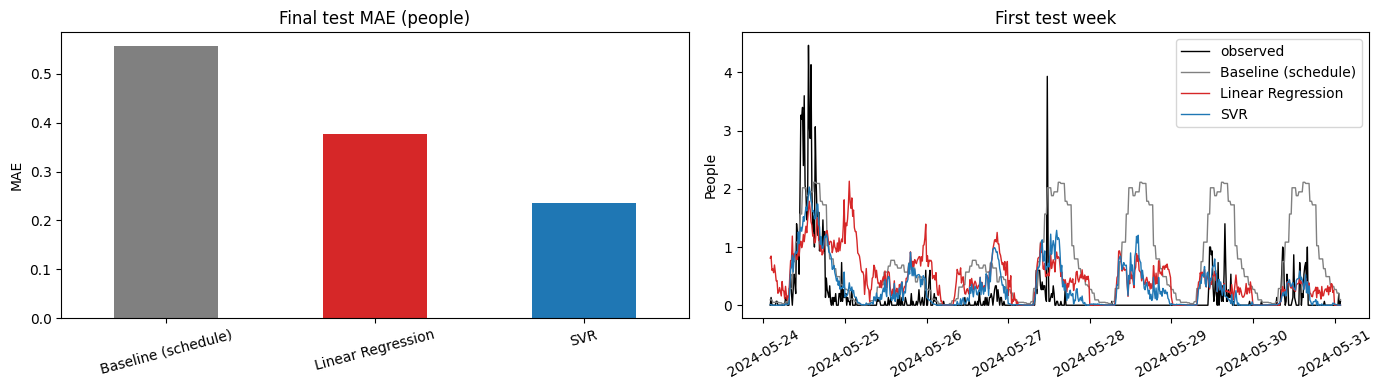

In [14]:
# ===== 12. Test Plots =====
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
test['MAE'].plot.bar(ax=ax[0], color=['grey', 'tab:red', 'tab:blue'], rot=15)
ax[0].set(title='Final test MAE (people)', ylabel='MAE')

n = 7 * 96                                           # first test week (96 x 15 min per day)
ax[1].plot(y_te.index[:n], y_te.values[:n], 'k', lw=1, label='observed')
for name, c in zip(FINAL_MODELS, ['grey', 'tab:red', 'tab:blue']):
    ax[1].plot(y_te.index[:n], preds[name][:n], color=c, lw=1, label=name)
ax[1].set(title='First test week', ylabel='People'); ax[1].legend(); ax[1].tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()

### 5e. Naive constant benchmark (reference only)

In [15]:
# ===== 13. Naive Constant Benchmark =====
from sklearn.dummy import DummyRegressor

naive = {}
for strat in ['mean', 'median']:
    m = DummyRegressor(strategy=strat).fit(X_tr, y_tr)      # constant learned from training data only
    naive[f'Constant ({strat} of training)'] = metrics(y_te, m.predict(X_te))
print('NAIVE CONSTANT BENCHMARKS (test set)')
print(pd.DataFrame(naive).T.round(3).to_string())

NAIVE CONSTANT BENCHMARKS (test set)
                                 MAE   RMSE     R2   bias
Constant (mean of training)    0.671  0.723 -0.856  0.491
Constant (median of training)  0.356  0.531 -0.000  0.012


### Appendix 1. Floorspace Mapping

In [16]:
from scipy.stats import spearmanr
from sklearn.dummy import DummyRegressor

TRAIN_END, TEST_START = '2024-05-23 23:45', '2024-05-24 02:00'    # identical to the main split

def to_occ(ev):
    # same conversion as the main workflow: event stream -> held state -> 15-min mean headcount
    t = pd.to_datetime(ev['collecteddate'], format='ISO8601', utc=True).dt.tz_convert(TZ).dt.tz_localize(None)
    s = pd.Series(pd.to_numeric(ev['headcount'], errors='coerce').to_numpy(), index=t).dropna().sort_index()
    s = s[~s.index.duplicated(keep='last')]
    s = s.resample('1min').last().ffill(limit=4320)
    return s.resample('15min', closed='right', label='right').mean().rename('occupancy')

# read the big file once, in chunks, keeping every floorspace but only the dates we need
parts = []
for c in pd.read_csv(OCC_CSV, usecols=['floorspaceid', 'headcount', 'collecteddate'], chunksize=1_000_000):
    d = c['collecteddate'].astype(str).str[:10]
    parts.append(c[(d >= '2024-02-20') & (d <= '2024-06-16')])
ev_all = pd.concat(parts)
occ_all = {fs: to_occ(g) for fs, g in ev_all.groupby('floorspaceid')}
print(len(occ_all), 'floorspaces:', [fs[:8] for fs in occ_all])

5 floorspaces: ['0f3f37f8', '227f1068', '3e5a14df', '941f0352', 'cca1ac3e']


In [17]:
def table_for(fs):
    d = env.join(occ_all[fs], how='inner').dropna(subset=['occupancy', 'co2'])
    d['hour'] = d.index.hour + d.index.minute / 60
    d['weekend'] = (d.index.dayofweek >= 5).astype(int)
    return d

# rule: choose the floorspace whose occupancy has the strongest CO2 association on the TRAINING period only
rows = []
for fs in occ_all:
    tr = table_for(fs).loc[:TRAIN_END]
    if len(tr) < 500:
        continue
    rows.append({'floorspace': fs[:8], 'train rows': len(tr), 'mean occupancy': tr['occupancy'].mean(),
                 'Spearman(CO2, occupancy)': spearmanr(tr['co2'], tr['occupancy'])[0]})
scan = pd.DataFrame(rows).set_index('floorspace').sort_values('Spearman(CO2, occupancy)', ascending=False)
print('FLOORSPACE SCAN (training period only)'); print(scan.round(3).to_string())
print('\nselected by this rule:', scan.index[0], '| used in main workflow:', FLOORSPACE[:8])

FLOORSPACE SCAN (training period only)
            train rows  mean occupancy  Spearman(CO2, occupancy)
floorspace                                                      
3e5a14df          2208           2.281                     0.626
941f0352          8091           0.746                     0.598
0f3f37f8          8091           0.821                     0.496
cca1ac3e          7811           0.858                     0.479
227f1068          7811           0.969                     0.440

selected by this rule: 3e5a14df | used in main workflow: 941f0352


In [18]:
# the same final models (no re-tuning) fitted and tested on every floorspace; same chronological split
rows = []
for fs in occ_all:
    d = table_for(fs)
    tr, te = d.loc[:TRAIN_END], d.loc[TEST_START:]
    if len(tr) < 500 or len(te) < 200:
        continue
    X_a, y_a, X_b, y_b = tr[FEATURES], tr['occupancy'], te[FEATURES], te['occupancy']
    models = dict(FINAL_MODELS)
    models['Constant (median)'] = lambda: DummyRegressor(strategy='median')
    for name, make in models.items():
        rows.append({'floorspace': fs[:8], 'model': name, 'test mean occ': y_b.mean(),
                     **metrics(y_b, make().fit(X_a, y_a).predict(X_b))})
sens = pd.DataFrame(rows)
print('SENSITIVITY: FINAL MODELS ON EACH FLOORSPACE (test set)')
print(sens.pivot(index='floorspace', columns='model', values='MAE').round(3).to_string())
print('\n(R2)')
print(sens.pivot(index='floorspace', columns='model', values='R2').round(3).to_string())

SENSITIVITY: FINAL MODELS ON EACH FLOORSPACE (test set)
model       Baseline (schedule)  Constant (median)  Linear Regression    SVR
floorspace                                                                  
0f3f37f8                  0.621              0.472              0.407  0.312
227f1068                  0.715              0.382              0.471  0.303
3e5a14df                  1.881              0.739              0.693  0.658
941f0352                  0.557              0.356              0.376  0.236
cca1ac3e                  0.671              0.456              0.543  0.404

(R2)
model       Baseline (schedule)  Constant (median)  Linear Regression    SVR
floorspace                                                                  
0f3f37f8                 -4.244             -1.124             -1.228 -0.491
227f1068                 -0.554             -0.071              0.025  0.156
3e5a14df                 -5.961             -0.231              0.155  0.134
941f0352      